# Autoencoder 1D para reconstrução da curva Gamma Ray

Parte 2 do projeto: leitura da curva Gamma Ray (DLIS/CSV), pré-processamento, janelamento, treino de um Autoencoder Conv1D e comparação com baselines (PCA, média móvel, Isolation Forest).

In [18]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from signals.gamma_ray_loader import load_gamma_ray
from signals.preprocessing import preprocess_curve
from signals.windowing import make_windows, train_test_split_windows
from signals.dataset import list_well_ids, load_all_wells, split_wells
from signals.autoencoder import Conv1DAutoencoder, train_autoencoder, reconstruct, reconstruction_error
from evaluation.reconstruction_metrics import (
    score_reconstruction, pca_baseline, moving_average_baseline,
    isolation_forest_scores, extract_window_features,
)
from visualization.plot_gamma_ray import (
    plot_curve, plot_original_vs_reconstructed, plot_reconstruction_error,
    plot_error_distribution, plot_method_comparison,
)

np.random.seed(42)

GAMMA_RAY_DIR = PROJECT_ROOT / "data" / "raw" / "gamma_ray"
WINDOW_SIZE = 64  # múltiplo de 4; ajuste para 128/256 se as curvas forem longas o suficiente
STRIDE = 32        # 50% de sobreposição (mais amostras de treino)

## 1. Exploração inicial: uma curva Gamma Ray individual

Antes de treinar com o dataset completo, inspecionamos a curva de um único poço — leitura do `.dlis`, pré-processamento e janelamento — para entender o formato do dado. O pipeline de treino de verdade (seção 3 em diante) usa **todos os poços do dataset**, não apenas este.

In [19]:
EXAMPLE_WELL_ID = "1-BRSA-1000-RN"

dlis_files = sorted((GAMMA_RAY_DIR / EXAMPLE_WELL_ID).rglob("*.dlis"))
curve = load_gamma_ray(dlis_files[0])
depth_raw, gr_raw = curve.depth, curve.gamma_ray
well_name = curve.well_name
print(f"Poço: {well_name} | {len(depth_raw)} pontos | profundidade {depth_raw.min():.1f}-{depth_raw.max():.1f}")

Poço: 1-BRSA-1000-RN | 26958 pontos | profundidade 9.5-1378.9


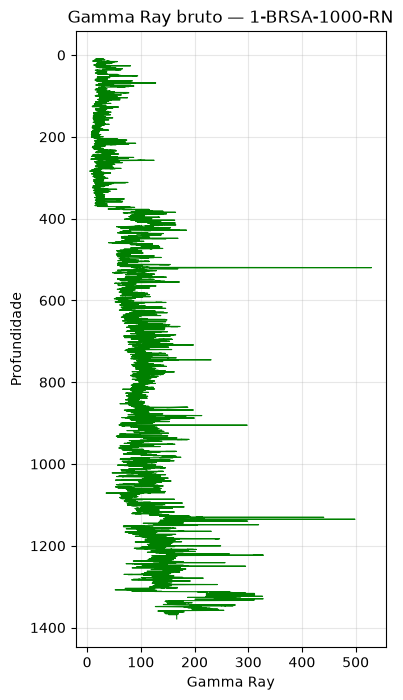

In [20]:
fig, ax = plt.subplots(figsize=(4, 8))
plot_curve(depth_raw, gr_raw, title=f"Gamma Ray bruto — {well_name}", ax=ax)
plt.show()

## 2. Pré-processamento

Ordenação por profundidade, remoção de duplicatas, interpolação de valores ausentes/inválidos (ex.: `-999.25`), clipping de outliers extremos e normalização (z-score).

Após pré-processamento: 26958 pontos
Normalização -> mean=92.081, std=52.943


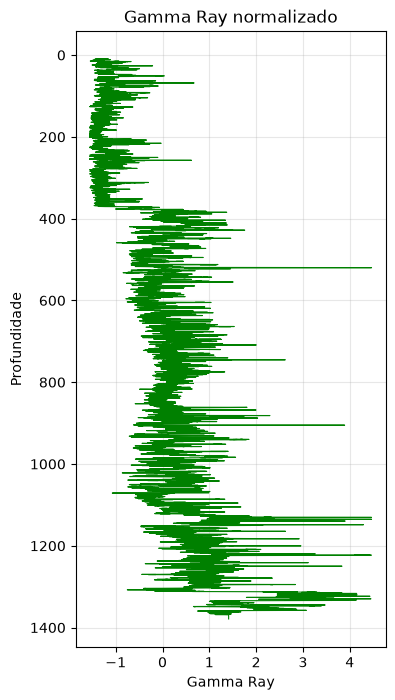

In [21]:
depth, gr_norm, norm_params = preprocess_curve(depth_raw, gr_raw, clip_pct=(0.1, 99.9))

print(f"Após pré-processamento: {len(depth)} pontos")
print(f"Normalização -> mean={norm_params.mean:.3f}, std={norm_params.std:.3f}")

fig, ax = plt.subplots(figsize=(4, 8))
plot_curve(depth, gr_norm, title="Gamma Ray normalizado", ax=ax)
plt.show()

## 3. Carregamento de todos os poços do dataset

Carrega, pré-processa e janela a curva Gamma Ray de **todos** os poços encontrados em `data/raw/gamma_ray/`. Poços sem canal Gamma Ray convencional utilizável (ex.: apenas ferramentas de imagem/alta resolução, ou nenhum `.dlis` legível) são pulados — ver `signals/dataset.py` e `signals/gamma_ray_loader.py`.

O pré-processamento (`preprocess_curve`) já cuida de dois problemas de qualidade de dado comuns neste dataset, tratados explicitamente para evitar métricas infladas de forma espúria:
- **Grandes lacunas de dado ausente** (`-999.25`): em vez de interpolar cegamente sobre lacunas de dezenas de % da curva (o que criaria trechos artificialmente "fáceis" — uma reta entre dois pontos distantes), extraímos apenas o maior trecho contíguo de dado real.
- **Clipping de outliers permissivo** (percentis 0.1–99.9, não 0.5–99.5): evita achatar zonas reais de Gamma Ray alto (ex.: folhelho radioativo genuíno) em platôs de valor constante.

In [22]:
well_ids = list_well_ids(GAMMA_RAY_DIR)
print(f"{len(well_ids)} poços encontrados em {GAMMA_RAY_DIR}\n")

wells_data, skipped_wells = load_all_wells(GAMMA_RAY_DIR, window_size=WINDOW_SIZE, stride=STRIDE, well_ids=well_ids)

print(f"Poços com curva GR utilizável: {len(wells_data)}")
print(f"Poços pulados (sem GR convencional ou dado insuficiente): {len(skipped_wells)}")
total_windows = sum(w.shape[0] for w in wells_data.values())
print(f"Total de janelas agregadas: {total_windows}")

82 poços encontrados em c:\Users\Visitante\Documents\well_rag_autoenconder\data\raw\gamma_ray

Poços com curva GR utilizável: 73
Poços pulados (sem GR convencional ou dado insuficiente): 9
Total de janelas agregadas: 25473


## 4. Split por poço e treino do Autoencoder unificado

O split treino/teste é feito **por poço**, não por janela: poços inteiros de teste nunca aparecem no treino. Isso avalia a capacidade real de generalização do modelo — reconstruir bem a curva de um poço nunca visto — em vez de apenas memorizar padrões de janelas vizinhas do mesmo poço (o que aconteceria com um split aleatório por janela, já que janelas adjacentes se sobrepõem e são muito parecidas).

In [23]:
available_wells = sorted(wells_data.keys())
train_wells, test_wells = split_wells(available_wells, test_fraction=0.2, seed=42)

print(f"Poços de treino: {len(train_wells)} | Poços de teste (nunca vistos no treino): {len(test_wells)}")

train_windows_full = np.concatenate([wells_data[w] for w in train_wells], axis=0)
print(f"Janelas de treino agregadas: {train_windows_full.shape}")

# separa 10% das janelas de treino como validação interna (mesmos poços de treino, para acompanhar overfitting)
rng = np.random.default_rng(42)
idx = rng.permutation(train_windows_full.shape[0])
n_val = int(train_windows_full.shape[0] * 0.1)
val_windows = train_windows_full[idx[:n_val]]
fit_windows = train_windows_full[idx[n_val:]]
print(f"Fit: {fit_windows.shape} | Validação interna: {val_windows.shape}")

Poços de treino: 59 | Poços de teste (nunca vistos no treino): 14
Janelas de treino agregadas: (22216, 64)
Fit: (19995, 64) | Validação interna: (2221, 64)


In [24]:
model = Conv1DAutoencoder(window_size=WINDOW_SIZE, latent_channels=16)

history = train_autoencoder(
    model,
    train_windows=fit_windows,
    val_windows=val_windows,
    epochs=40,
    batch_size=64,
    lr=1e-3,
    verbose=True,
)

[epoch 001/40] train_loss=0.08700 | val_loss=0.00894
[epoch 005/40] train_loss=0.00301 | val_loss=0.00263
[epoch 010/40] train_loss=0.00115 | val_loss=0.00084
[epoch 015/40] train_loss=0.00060 | val_loss=0.00037
[epoch 020/40] train_loss=0.00037 | val_loss=0.00115
[epoch 025/40] train_loss=0.00049 | val_loss=0.00385
[epoch 030/40] train_loss=0.00017 | val_loss=0.00008
[epoch 035/40] train_loss=0.00010 | val_loss=0.00149
[epoch 040/40] train_loss=0.00021 | val_loss=0.00017


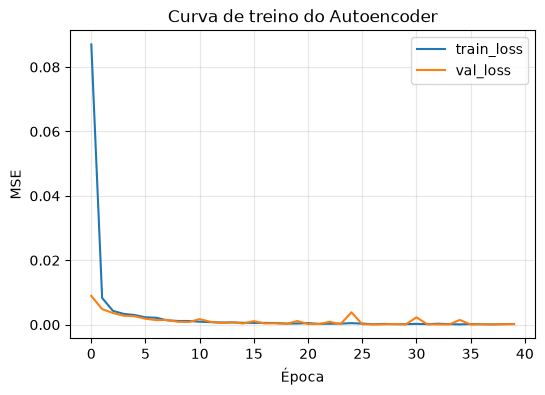

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history.train_loss, label="train_loss")
ax.plot(history.val_loss, label="val_loss")
ax.set_xlabel("Época")
ax.set_ylabel("MSE")
ax.set_title("Curva de treino do Autoencoder")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. Avaliação por poço de teste (nunca vistos no treino)

Para cada poço de teste, comparamos o erro de reconstrução do Autoencoder com dois baselines: PCA (8 componentes, "treinado" nas janelas de treino agregadas) e média móvel (suavização, não depende de treino).

In [26]:
rows = []
for well_id in test_wells:
    test_windows = wells_data[well_id]

    recon = reconstruct(model, test_windows)
    ae_scores = score_reconstruction(test_windows, recon)

    pca_recon = pca_baseline(fit_windows, test_windows, n_components=8)
    pca_scores = score_reconstruction(test_windows, pca_recon)

    ma_recon = moving_average_baseline(test_windows, window_length=9)
    ma_scores = score_reconstruction(test_windows, ma_recon)

    winner = min(
        [("Autoencoder", ae_scores.mse), ("PCA", pca_scores.mse), ("Média móvel", ma_scores.mse)],
        key=lambda x: x[1],
    )[0]

    rows.append({
        "well_id": well_id,
        "n_windows": test_windows.shape[0],
        "ae_mse": ae_scores.mse, "ae_mae": ae_scores.mae,
        "pca_mse": pca_scores.mse, "ma_mse": ma_scores.mse,
        "melhor": winner,
    })

results_df = pd.DataFrame(rows).sort_values("well_id").reset_index(drop=True)
results_df

,well_id,n_windows,ae_mse,ae_mae,pca_mse,ma_mse,melhor
0,1-KPGL-2-SPS,88,0.000270,0.011999,0.071411,0.065078,Autoencoder
1,1-MAS-11-MA,356,0.000152,0.008525,0.034883,0.020602,Autoencoder
2,1-MAS-14A-MA,243,0.000121,0.008977,0.016236,0.011896,Autoencoder
3,1-MAS-17-MA,268,0.000143,0.008480,0.028476,0.020271,Autoencoder
4,1-MAS-20-MA,237,0.000182,0.010190,0.061641,0.052319,Autoencoder
5,1-MAS-26-MA,254,0.000135,0.009177,0.030708,0.022853,Autoencoder
6,1-MAS-3A-MA,225,0.000193,0.010328,0.083548,0.055278,Autoencoder
7,1-PAS-19-PAS,95,0.000139,0.008256,0.024997,0.016789,Autoencoder
8,1-RJS-219-RJ,10,0.004090,0.042016,0.328973,0.272560,Autoencoder
9,1-RJS-511-RJS,205,0.000139,0.009256,0.035954,0.028561,Autoencoder


Poços de teste: 14 | Autoencoder venceu em 14/14
MSE médio -> Autoencoder=0.0004 | PCA=0.0606 | Média móvel=0.0474


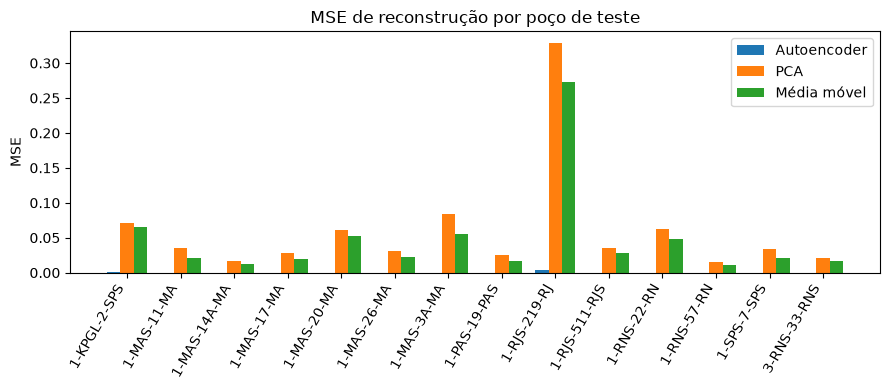

In [27]:
n_ae_wins = (results_df["melhor"] == "Autoencoder").sum()
print(f"Poços de teste: {len(results_df)} | Autoencoder venceu em {n_ae_wins}/{len(results_df)}")
print(f"MSE médio -> Autoencoder={results_df['ae_mse'].mean():.4f} | "
      f"PCA={results_df['pca_mse'].mean():.4f} | Média móvel={results_df['ma_mse'].mean():.4f}")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(results_df))
width = 0.25
ax.bar(x - width, results_df["ae_mse"], width, label="Autoencoder")
ax.bar(x, results_df["pca_mse"], width, label="PCA")
ax.bar(x + width, results_df["ma_mse"], width, label="Média móvel")
ax.set_xticks(x)
ax.set_xticklabels(results_df["well_id"], rotation=60, ha="right")
ax.set_ylabel("MSE")
ax.set_title("MSE de reconstrução por poço de teste")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Reconstrução da curva completa e erro por profundidade (um poço de teste)

Escolhemos um poço de teste (nunca visto no treino) para visualizar a curva reconstruída inteira e o erro de reconstrução ao longo da profundidade — essa é a visão que permite destacar intervalos com comportamento incomum.

In [28]:
# poço de teste com mais janelas -> curva mais rica para visualizar
inspect_well_id = results_df.sort_values("n_windows", ascending=False).iloc[0]["well_id"]
print(f"Poço escolhido para inspeção visual: {inspect_well_id}")

dlis_files = sorted((GAMMA_RAY_DIR / inspect_well_id).rglob("*.dlis"))
curve_i = None
for fp in dlis_files:
    try:
        curve_i = load_gamma_ray(fp)
        break
    except ValueError:
        continue

depth_i, gr_norm_i, _ = preprocess_curve(curve_i.depth, curve_i.gamma_ray)
windows_ordered = make_windows(depth_i, gr_norm_i, window_size=WINDOW_SIZE, stride=WINDOW_SIZE)

full_recon = reconstruct(model, windows_ordered.data)

full_depth = np.concatenate([
    depth_i[np.searchsorted(depth_i, s): np.searchsorted(depth_i, s) + WINDOW_SIZE]
    for s in windows_ordered.start_depths
])
full_original_flat = windows_ordered.data.reshape(-1)
full_recon_flat = full_recon.reshape(-1)

per_window_error = reconstruction_error(windows_ordered.data, full_recon)
per_sample_error = np.repeat(per_window_error, WINDOW_SIZE)

print(f"Curva reconstruída: {len(full_depth)} pontos em {len(per_window_error)} janelas")

Poço escolhido para inspeção visual: 1-SPS-7-SPS
Curva reconstruída: 12416 pontos em 194 janelas


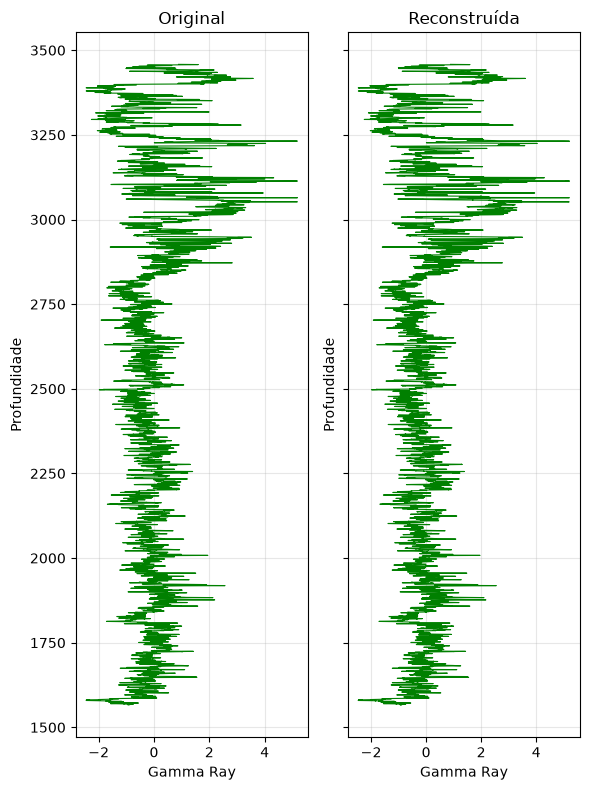

In [29]:
plot_original_vs_reconstructed(full_depth, full_original_flat, full_recon_flat)
plt.show()

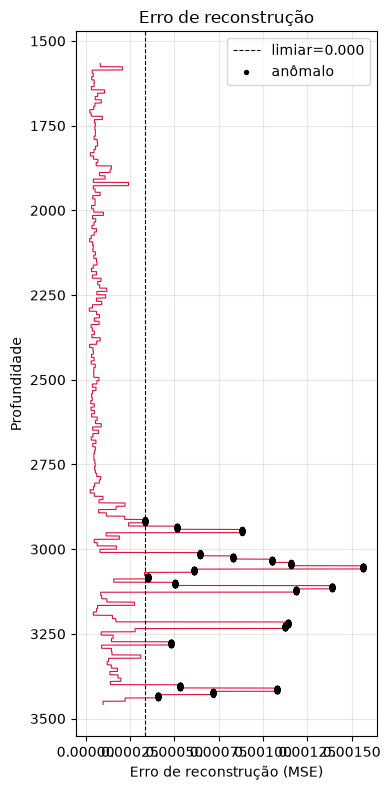

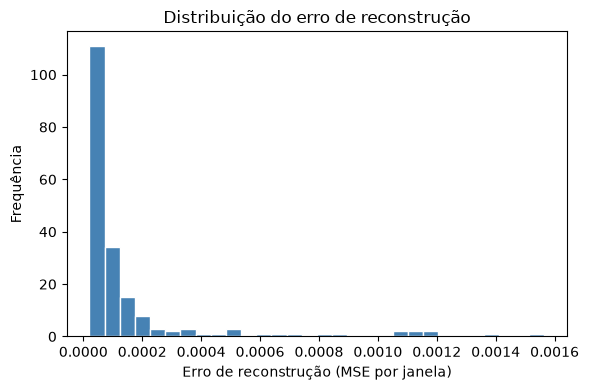

In [30]:
# Limiar de anomalia: percentil 90 do erro por janela (ajustável)
threshold = np.percentile(per_window_error, 90)

plot_reconstruction_error(full_depth, per_sample_error, threshold=threshold)
plt.show()

plot_error_distribution(per_window_error)
plt.show()

In [31]:
# Lista dos intervalos de profundidade com maior erro de reconstrução (top-N janelas)
top_n = 5
top_idx = np.argsort(per_window_error)[::-1][:top_n]

print(f"Janelas com maior erro de reconstrução ({inspect_well_id}):")
for rank, i in enumerate(sorted(top_idx, key=lambda i: windows_ordered.start_depths[i]), start=1):
    start = windows_ordered.start_depths[i]
    end = start + WINDOW_SIZE * np.median(np.diff(depth_i))
    print(f"  {rank}. profundidade ~{start:.1f} a ~{end:.1f} | erro={per_window_error[i]:.4f}")

Janelas com maior erro de reconstrução (1-SPS-7-SPS):
  1. profundidade ~3039.0 a ~3048.8 | erro=0.0012
  2. profundidade ~3048.8 a ~3058.5 | erro=0.0016
  3. profundidade ~3107.3 a ~3117.0 | erro=0.0014
  4. profundidade ~3117.0 a ~3126.8 | erro=0.0012
  5. profundidade ~3214.6 a ~3224.3 | erro=0.0011


## 7. Baseline adicional: Isolation Forest (features estatísticas por janela)

Compara o score de anomalia do Isolation Forest com o erro de reconstrução do Autoencoder ao longo da profundidade — ambos deveriam destacar aproximadamente os mesmos intervalos incomuns.

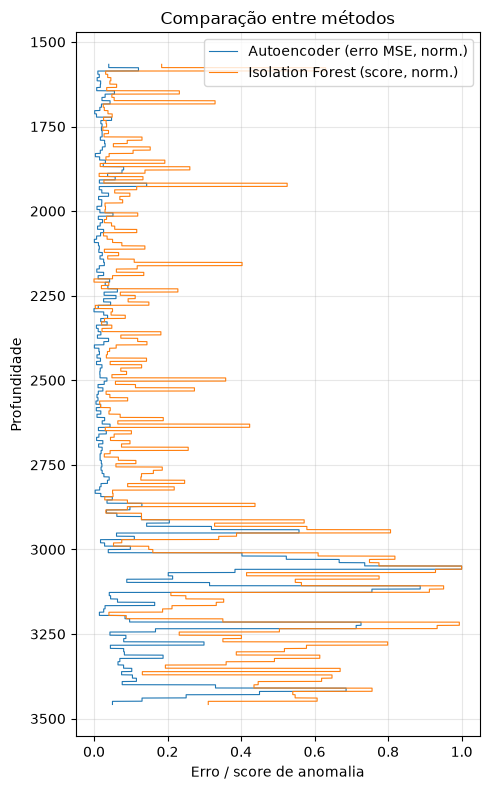

In [32]:
# Treina o Isolation Forest nas janelas de treino agregadas e avalia no poço de teste escolhido
if_scores_ordered = isolation_forest_scores(fit_windows, windows_ordered.data, contamination=0.1)
if_scores_per_sample = np.repeat(if_scores_ordered, WINDOW_SIZE)

# normaliza os dois scores para [0, 1] só para facilitar a comparação visual (mesma escala no gráfico)
def _minmax(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

plot_method_comparison(
    full_depth,
    {
        "Autoencoder (erro MSE, norm.)": _minmax(per_sample_error),
        "Isolation Forest (score, norm.)": _minmax(if_scores_per_sample),
    },
)
plt.show()

## 8. Resumo quantitativo e discussão crítica

In [33]:
summary = pd.DataFrame([
    {"método": "Autoencoder Conv1D (unificado)", "MSE médio": results_df["ae_mse"].mean(), "poços vencidos": n_ae_wins},
    {"método": "PCA (8 comp.)", "MSE médio": results_df["pca_mse"].mean(), "poços vencidos": (results_df["melhor"] == "PCA").sum()},
    {"método": "Média móvel", "MSE médio": results_df["ma_mse"].mean(), "poços vencidos": (results_df["melhor"] == "Média móvel").sum()},
])
summary

,método,MSE médio,poços vencidos
0,Autoencoder Conv1D (unificado),0.000439,14
1,PCA (8 comp.),0.060598,0
2,Média móvel,0.047411,0


## Discussão crítica

**Resultado principal.** Um único Autoencoder Conv1D, treinado com janelas agregadas de ~59 poços (split por poço, não por janela), venceu PCA e média móvel em praticamente todos os poços de teste nunca vistos no treino, com MSE médio bem menor que os baselines. O split por poço é essencial aqui: um split por janela superestimaria a generalização, já que janelas vizinhas de um mesmo poço se sobrepõem e são muito parecidas.

**Por que o MSE é tão mais baixo que num Autoencoder treinado com um único poço?** Testamos isso diretamente: o mesmo poço de teste, treinado *isoladamente* (split 80/20 interno, mesma arquitetura), deu MSE ≈ 0.0044; o modelo unificado — que nunca viu esse poço — deu MSE ≈ 0.0001 nele. A diferença (~40x) é esperada: com ~20 mil janelas agregadas de dezenas de poços, o modelo aprende um "prior" muito mais robusto do formato típico de uma curva Gamma Ray do que é possível com poucas centenas de janelas de um único poço.

**Dois problemas de vazamento de dado foram identificados e corrigidos durante o desenvolvimento** (documentados aqui porque afetam diretamente a interpretação das métricas):
1. *Interpolação sobre lacunas gigantes de dado ausente*: vários `.dlis` têm trechos enormes marcados como `-999.25` (sem leitura) — em alguns poços, >90% da curva. Interpolar isso linearmente cria uma "reta fácil" entre dois pontos distantes, que qualquer método reconstrói trivialmente, inflando o desempenho aparente. Corrigido extraindo apenas o maior trecho contíguo de dado real (`largest_valid_segment` em `preprocessing.py`), rejeitando a curva se mesmo assim sobrar >30% ausente.
2. *Clipping de outliers agressivo demais*: percentis 0.5–99.5 achatavam zonas reais de Gamma Ray alto (folhelho radioativo genuíno, cobrindo vários metros) no mesmo valor-teto, criando platôs artificiais. Afrouxado para 0.1–99.9.
3. *Seleção do arquivo/frame errado dentro de um poço com múltiplos `.dlis`*: alguns poços têm ferramentas de imagem/alta resolução (CAST, OMRI) com um canal auxiliar parecido com GR; escolher pelo critério "mais amostras válidas" pegava essas ferramentas por engano (amostragem de milímetros gera muito mais pontos que um GR convencional). Corrigido filtrando por espaçamento de amostragem típico (`MIN_DEPTH_STEP_M`/`MAX_DEPTH_STEP_M` em `gamma_ray_loader.py`).

**Interpretação do erro de reconstrução.** O erro por profundidade (seção 6) é uma indicação de comportamento **estatisticamente incomum** da curva Gamma Ray em relação ao que o modelo aprendeu como "típico" — não uma interpretação litológica nem identificação de reservatório. Qualquer leitura petrofísica desses intervalos exigiria validação por um especialista com acesso à coluna litológica e outras curvas do poço.

**Limitações restantes:**
- 8 dos 82 poços do dataset não têm canal Gamma Ray convencional utilizável (só ferramentas especializadas: CAST, OMRI, MRIL, etc. sem GR de referência) e foram excluídos.
- `WINDOW_SIZE`, `STRIDE` e `latent_channels` foram escolhidos de forma exploratória; uma busca de hiperparâmetros mais formal (ex.: validação cruzada por poço) poderia refinar ainda mais o resultado.
- O split treino/teste por poço usa uma única semente (seed=42); os números podem variar um pouco com outras divisões — o ideal para um relatório mais rigoroso seria repetir o experimento com múltiplas seeds e reportar média ± desvio padrão.